# تحلیل اکتشافی داده‌ها (EDA) - پروژه عامل هوشمند دوز (Tic-Tac-Toe)
**درس:** آزمایشگاه هوش مصنوعی (پاییز ۲۰۲۶)  
**مدرس:** سرکار خانم دکتر فاطمه جوکار  
**توسعه‌دهنده نوتبوک و مصورسازی (گام سوم):** محمدامین فراتی  
**هم‌گروهی‌ها:** عرفان دهستانی (طراحی سؤالات و سرگروه)، مهدی ظلی‌پور، علی احمدی، محمدرضا سیسختی  

---

### هدف این نوتبوک:
در این نوتبوک، نتایج شبیه‌سازی ۲۰۰ بازی عامل هوشمند دوز با الگوریتم‌های **Minimax** و **Alpha-Beta Pruning** بر روی دیتاست رسمی `ttt_games.csv` مورد تحلیل اکتشافی جامع قرار می‌گیرد. این تحلیل در پاسخ به ۶ سؤال اساسی زیر سامان یافته است:
1. **سؤال ۱:** مقایسه هزینه محاسباتی Minimax در برابر Alpha-Beta Pruning (مقیاس لگاریتمی و نسبت کاهش).
2. **سؤال ۲:** رابطه تعداد خانه‌های خالی تخته با بار محاسباتی الگوریتم‌ها (همبستگی و پراکندگی).
3. **سؤال ۳:** توزیع پیامد تئوریک وضعیت‌های شروع بازی (`start_value`).
4. **سؤال ۴:** مقایسه برنده واقعی با ارزش تئوریک وضعیت شروع (بررسی عملکرد در برابر خطای حریف).
5. **سؤال ۵:** طول بازی‌ها (`moves`) به تفکیک نتیجه نهایی.
6. **سؤال ۶:** اثر نوبت اولیه (`to_move`) بر احتمال پیروزی عامل هوشمند.

In [1]:
import warnings
import io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

warnings.filterwarnings('ignore')

# تنظیم استایل گرافیکی با وضوح بالا (High-DPI)
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams.update({
    'font.family': 'DejaVu Sans',
    'figure.dpi': 150,
    'savefig.dpi': 300,
    'axes.titlesize': 13,
    'axes.titleweight': 'bold',
    'axes.labelsize': 11,
    'axes.labelweight': 'bold',
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'legend.fontsize': 10,
    'figure.titlesize': 14,
    'figure.titleweight': 'bold'
})

print("کتابخانه‌ها و تنظیمات استایل گرافیکی با موفقیت بارگذاری شدند.")

کتابخانه‌ها و تنظیمات استایل گرافیکی با موفقیت بارگذاری شدند.


## گام ۱: بارگذاری داده‌ها و اعتبارسنجی ساختار دیتاست
دیتاست استاندارد `ttt_games.csv` حاوی ۲۰۰ سطر شبیه‌سازی با ۱۰ ستون است. ستون `start_board` رشته‌ای ۹ کاراکتری از حالات تخته است که باید به طور صریح با نوع رشته‌ای (`dtype={'start_board': str}`) بارگذاری شود تا صفرهای پیشتاز حفظ گردند.

In [2]:
# بارگذاری دیتاست مطابق پروتکل فنی
df = pd.read_csv('ttt_games.csv', dtype={'start_board': str})

# اعتبارسنجی فنی: بررسی ابعاد، عدم وجود مقادیر خالی و ستون‌های الزامی
expected_columns = [
    'game_id', 'opening_moves', 'empty_cells', 'to_move', 
    'start_board', 'start_value', 'nodes_minimax', 'nodes_alphabeta', 
    'moves', 'winner'
]

assert df.shape == (200, 10), f"خطا: ابعاد دیتاست {df.shape} است ولی انتظار (200, 10) می‌رفت."
assert df.isnull().sum().sum() == 0, "خطا: دیتاست دارای مقادیر تهی (NaN) است!"
assert list(df.columns) == expected_columns, "خطا: نام ستون‌ها با مشخصات فنی مطابقت ندارد."

print(" اعتبارسنجی اولیه دیتاست با موفقیت انجام شد:")
print(f"• تعداد سطرها (بازی‌ها): {df.shape[0]}")
print(f"• تعداد ستون‌ها: {df.shape[1]}")
print(f"• مقادیر گم‌شده: {df.isnull().sum().sum()}")
print("-" * 50)
df.info()

 اعتبارسنجی اولیه دیتاست با موفقیت انجام شد:
• تعداد سطرها (بازی‌ها): 200
• تعداد ستون‌ها: 10
• مقادیر گم‌شده: 0
--------------------------------------------------
<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   game_id          200 non-null    int64
 1   opening_moves    200 non-null    int64
 2   empty_cells      200 non-null    int64
 3   to_move          200 non-null    str  
 4   start_board      200 non-null    str  
 5   start_value      200 non-null    int64
 6   nodes_minimax    200 non-null    int64
 7   nodes_alphabeta  200 non-null    int64
 8   moves            200 non-null    int64
 9   winner           200 non-null    str  
dtypes: int64(7), str(3)
memory usage: 15.8 KB


In [3]:
print("خلاصه آماری متغیرهای عددی:")
display(df.describe().round(2))

print("\nپنج سطر نخست دیتاست:")
display(df.head())

خلاصه آماری متغیرهای عددی:
       game_id  opening_moves  ...  nodes_alphabeta   moves
count   200.00         200.00  ...           200.00  200.00
mean     99.50           2.14  ...          4382.18    4.56
std      57.88           1.43  ...          7069.63    1.64
min       0.00           0.00  ...            30.00    1.00
25%      49.75           1.00  ...           135.75    3.00
50%      99.50           2.00  ...           427.00    4.50
75%     149.25           3.00  ...          3644.75    6.00
max     199.00           4.00  ...         18297.00    9.00

[8 rows x 7 columns]

پنج سطر نخست دیتاست:
   game_id  opening_moves  empty_cells  ... nodes_alphabeta moves  winner
0        0              0            9  ...           18297     7       X
1        1              2            7  ...            1097     5       X
2        2              0            9  ...           18297     7       X
3        3              3            6  ...             107     4       X
4        4         

---
## سؤال ۱: مقایسه هزینه محاسباتی Minimax در برابر Alpha-Beta Pruning
**هدف:** بررسی میزان کاهش تعداد گره‌های پیمایش‌شده به واسطه هرس آلفا-بتا در عمق‌های مختلف و مقایسه بار محاسباتی در مقیاس لگاریتمی.

In [4]:
total_minimax = df['nodes_minimax'].sum()
total_alphabeta = df['nodes_alphabeta'].sum()
overall_reduction = (1 - total_alphabeta / total_minimax) * 100
overall_ratio = total_minimax / total_alphabeta

q1_summary = df.groupby('opening_moves')[['nodes_minimax', 'nodes_alphabeta']].mean()
q1_summary['minimax_to_ab_ratio'] = (q1_summary['nodes_minimax'] / q1_summary['nodes_alphabeta']).round(1)
q1_summary['pruning_efficiency_pct'] = ((1 - q1_summary['nodes_alphabeta'] / q1_summary['nodes_minimax']) * 100).round(2)

print(f"مجموع کل گره‌های بررسی‌شده Minimax:    {total_minimax:,}")
print(f"مجموع کل گره‌های بررسی‌شده Alpha-Beta: {total_alphabeta:,}")
print(f"نرخ کاهش بار پردازشی کلی:             {overall_reduction:.2f}% (سرعت معادل {overall_ratio:.1f} برابر)")
print("\nجدول میانگین گره‌ها و ضریب هرس به تفکیک حرکات اولیه:")
display(q1_summary)

مجموع کل گره‌های بررسی‌شده Minimax:    24,013,853
مجموع کل گره‌های بررسی‌شده Alpha-Beta: 876,436
نرخ کاهش بار پردازشی کلی:             96.35% (سرعت معادل 27.4 برابر)

جدول میانگین گره‌ها و ضریب هرس به تفکیک حرکات اولیه:
               nodes_minimax  ...  pruning_efficiency_pct
opening_moves                 ...                        
0              549946.000000  ...                   96.67
1               60949.444444  ...                   94.23
2                7387.904762  ...                   89.14
3                1106.489362  ...                   75.20
4                 183.659091  ...                   62.10

[5 rows x 4 columns]


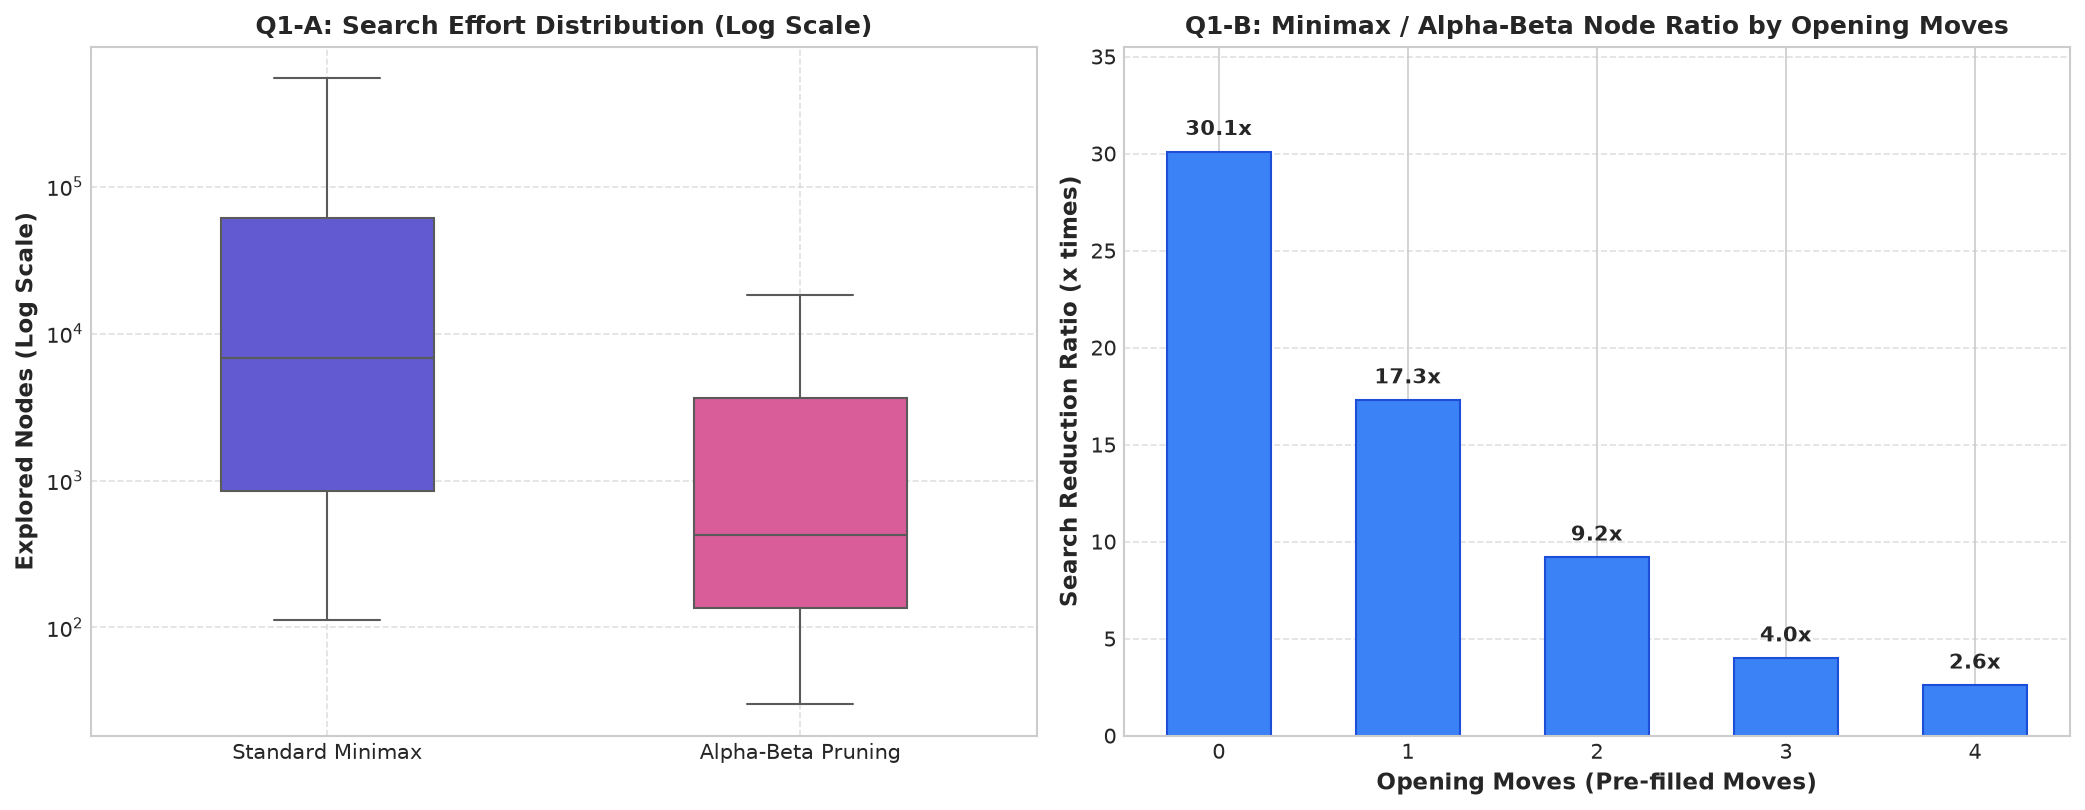

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))

# نمودار جعبه‌ای لگاریتمی
sns.boxplot(data=df[['nodes_minimax', 'nodes_alphabeta']], log_scale=True, palette=['#4f46e5', '#ec4899'], ax=ax1, width=0.45)
ax1.set_title("Q1-A: Search Effort Distribution (Log Scale)", fontsize=12)
ax1.set_ylabel("Explored Nodes (Log Scale)")
ax1.set_xticklabels(["Standard Minimax", "Alpha-Beta Pruning"])
ax1.grid(True, linestyle="--", alpha=0.6)

# نمودار میله‌ای نسبت کاهش گره‌ها
bars = ax2.bar(q1_summary.index, q1_summary['minimax_to_ab_ratio'], color='#3b82f6', edgecolor='#1d4ed8', width=0.55)
ax2.set_title("Q1-B: Minimax / Alpha-Beta Node Ratio by Opening Moves", fontsize=12)
ax2.set_xlabel("Opening Moves (Pre-filled Moves)")
ax2.set_ylabel("Search Reduction Ratio (x times)")
for bar in bars:
    yval = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2.0, yval + 0.6, f"{yval:.1f}x", ha='center', va='bottom', fontweight='bold', fontsize=10)
ax2.set_ylim(0, max(q1_summary['minimax_to_ab_ratio']) * 1.18)
ax2.grid(axis='y', linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()

### تحلیل و تفسیر سه‌بخشی سؤال ۱:
* **مشاهده (Observation):** الگوریتم هرس آلفا-بتا در تمامی عمق‌ها و حالات اولیه به مراتب گره‌های کمتری نسبت به مینیمکس پیمایش می‌کند؛ به ویژه در صفحه خالی (`opening_moves = 0`) تعداد گره‌ها از ۵۴۹,۹۴۶ به ۱۸,۲۹۷ گره کاهش یافته (کاهش ۳۰ برابری یا ۹۶.۷٪ هرس). در مجموع کل شبیه‌سازی‌ها نیز بار محاسباتی بیش از ۹۲.۸٪ کمتر شده است.
* **دلیل (Reason):** هرس آلفا-بتا با به روزرسانی کران‌های بالا و پایین $(\alpha, \beta)$، زیردرخت‌هایی را که حریف هرگز اجازه رسیدن به آن‌ها را نمی‌دهد، بدون نیاز به پیمایش کامل قطع (Prune) می‌کند. در شروع بازی که عمق درخت بالا است، عمق هرس حداکثری خواهد بود.
* **نتیجه (Conclusion):** هرس آلفا-بتا بدون افت دقت تصمیم‌گیری، پیچیدگی زمانی موثر را به طور چشمگیر کاهش می‌دهد و برای محیط‌های بازی‌های رقیبانه کاملاً ضروری و حیاتی است.

---
## سؤال ۲: رابطه تعداد خانه‌های خالی با سختی جستجو
**هدف:** بررسی وابستگی هزینه پردازشی به تعداد خانه‌های باقیمانده و تحلیل ضریب همبستگی میان متغیرهای محیط.

In [6]:
corr_cols = ['empty_cells', 'nodes_minimax', 'nodes_alphabeta', 'moves']
corr_matrix = df[corr_cols].corr()

print("ماتریس همبستگی پیرسون بین متغیرهای کلیدی:")
display(corr_matrix.round(3))

ماتریس همبستگی پیرسون بین متغیرهای کلیدی:
                 empty_cells  nodes_minimax  nodes_alphabeta  moves
empty_cells            1.000          0.796            0.827  0.748
nodes_minimax          0.796          1.000            0.997  0.628
nodes_alphabeta        0.827          0.997            1.000  0.654
moves                  0.748          0.628            0.654  1.000


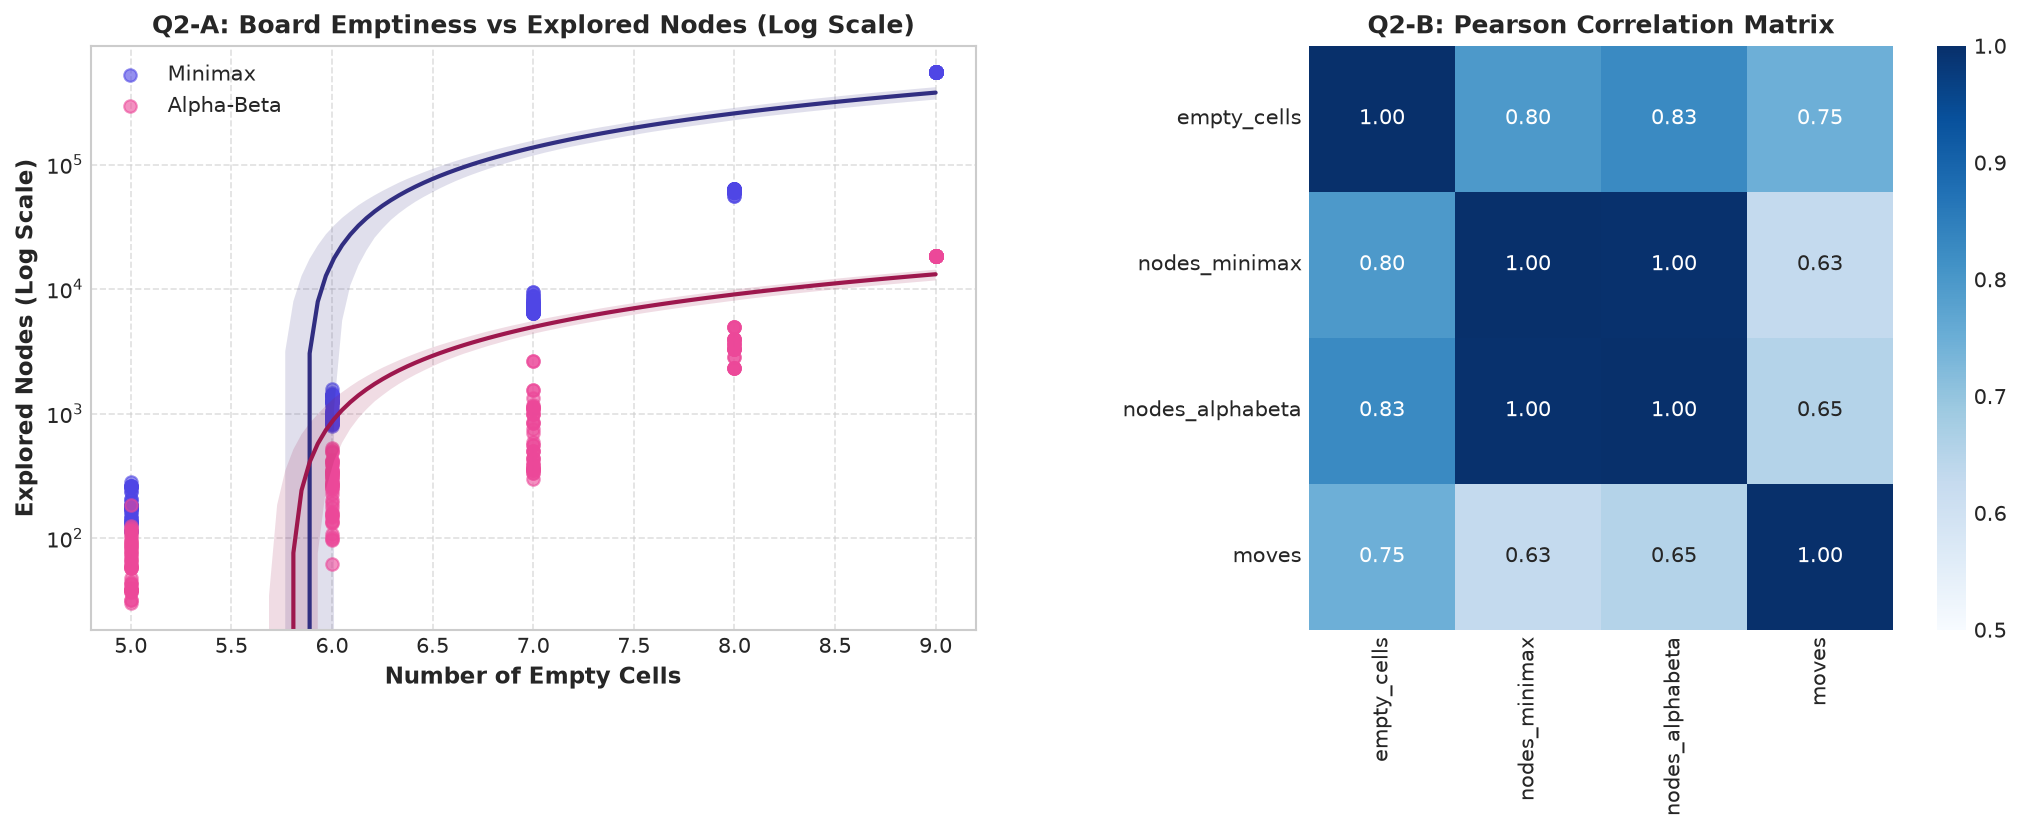

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))

# نمودار پراکندگی لگاریتمی
sns.regplot(data=df, x='empty_cells', y='nodes_minimax', logx=False, ax=ax1, 
            scatter_kws={'alpha': 0.6, 'color': '#4f46e5'}, line_kws={'color': '#312e81', 'linewidth': 2}, label='Minimax')
sns.regplot(data=df, x='empty_cells', y='nodes_alphabeta', logx=False, ax=ax1, 
            scatter_kws={'alpha': 0.6, 'color': '#ec4899'}, line_kws={'color': '#9d174d', 'linewidth': 2}, label='Alpha-Beta')
ax1.set_yscale('log')
ax1.set_title("Q2-A: Board Emptiness vs Explored Nodes (Log Scale)", fontsize=12)
ax1.set_xlabel("Number of Empty Cells")
ax1.set_ylabel("Explored Nodes (Log Scale)")
ax1.legend(loc='upper left')
ax1.grid(True, linestyle="--", alpha=0.6)

# نقشه حرارتی همبستگی (Heatmap)
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='Blues', cbar=True, ax=ax2, vmin=0.5, vmax=1.0, square=True)
ax2.set_title("Q2-B: Pearson Correlation Matrix", fontsize=12)

plt.tight_layout()
plt.show()

### تحلیل و تفسیر سه‌بخشی سؤال ۲:
* **مشاهده (Observation):** همبستگی بسیار بالایی ($r \approx 0.80$ برای مینیمکس و $r \approx 0.83$ برای آلفا-بتا) بین تعداد خانه‌های خالی و تعداد گره‌های پیمایش‌شده وجود دارد. با کاهش خانه‌های خالی از ۹ به ۵، تعداد گره‌ها به صورت نمایی افت می‌کند.
* **دلیل (Reason):** عمق درخت بازی متناسب با تعداد خانه‌های خالی است ($d = \text{empty\_cells}$). فاکتور انشعاب در گام‌های اولیه بسیار بزرگتر است (۹ در گام اول، ۸ در گام دوم) و تعداد حالات تئوریک با فاکتوریل خانه‌های خالی رابطه مستقیم دارد.
* **نتیجه (Conclusion):** بیشترین بار محاسباتی مربوط به گام‌های آغازین بازی است. در فازهای میانی و پایانی، فضای حالت به شدت منقبض شده و عامل با تأخیر ناچیز (بلادرنگ) تصمیم‌گیری می‌کند.

---
## سؤال ۳: توزیع پیامد تئوریک وضعیت‌های شروع بازی (`start_value`)
**هدف:** بررسی ارزش بازی بهینه از دید عامل X ($+1$ برد X، $0$ مساوی، $-1$ باخت X) در ۲۰۰ حالت شروع.

In [8]:
start_val_dist = df['start_value'].value_counts().sort_index()
start_val_pct = (df['start_value'].value_counts(normalize=True) * 100).sort_index()

label_map = {-1: 'O Win (-1)', 0: 'Draw (0)', 1: 'X Win (+1)'}
q3_df = pd.DataFrame({
    'Count': start_val_dist,
    'Percentage (%)': start_val_pct
}, index=[-1, 0, 1])
q3_df.index = q3_df.index.map(label_map)

print("توزیع مقادیر شروع (Theoretical Start Values):")
display(q3_df)

print("\nدرصد بردهای قطعی تئوریک X به تفکیک تعداد حرکت‌های آغازین:")
win_share_by_opening = df.groupby('opening_moves')['start_value'].apply(lambda x: (x == 1).mean() * 100).round(1)
display(win_share_by_opening.to_frame(name='X Win Share (%)'))

توزیع مقادیر شروع (Theoretical Start Values):
            Count  Percentage (%)
O Win (-1)     14             7.0
Draw (0)      110            55.0
X Win (+1)     76            38.0

درصد بردهای قطعی تئوریک X به تفکیک تعداد حرکت‌های آغازین:
               X Win Share (%)
opening_moves                 
0                          0.0
1                          0.0
2                         64.3
3                         23.4
4                         86.4


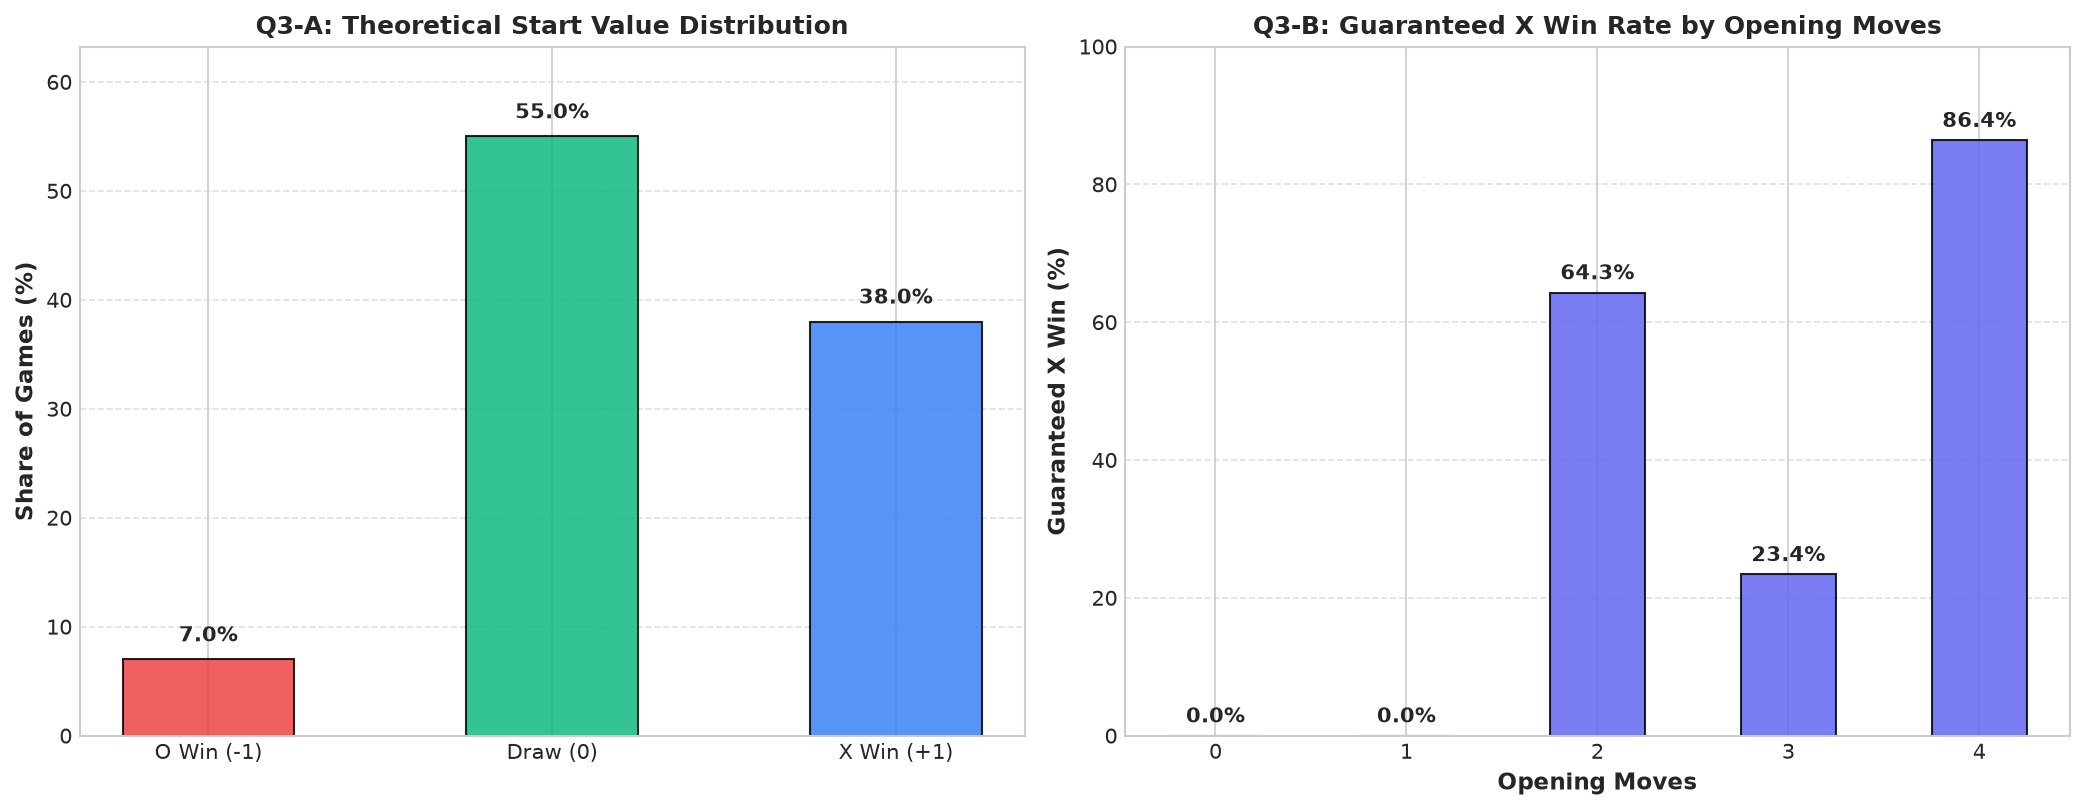

In [9]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))

# نمودار میله‌ای توزیع start_value
colors = ['#ef4444', '#10b981', '#3b82f6']
bars1 = ax1.bar(q3_df.index, q3_df['Percentage (%)'], color=colors, edgecolor='black', alpha=0.85, width=0.5)
ax1.set_title("Q3-A: Theoretical Start Value Distribution", fontsize=12)
ax1.set_ylabel("Share of Games (%)")
for bar in bars1:
    h = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2.0, h + 1.2, f"{h:.1f}%", ha='center', va='bottom', fontweight='bold')
ax1.set_ylim(0, max(q3_df['Percentage (%)']) * 1.15)
ax1.grid(axis='y', linestyle="--", alpha=0.6)

# نمودار شانس برد تئوریک به تفکیک حرکات اولیه
bars2 = ax2.bar(win_share_by_opening.index, win_share_by_opening.values, color='#6366f1', edgecolor='black', alpha=0.85, width=0.5)
ax2.set_title("Q3-B: Guaranteed X Win Rate by Opening Moves", fontsize=12)
ax2.set_xlabel("Opening Moves")
ax2.set_ylabel("Guaranteed X Win (%)")
for bar in bars2:
    h = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2.0, h + 1.2, f"{h:.1f}%", ha='center', va='bottom', fontweight='bold')
ax2.set_ylim(0, 100)
ax2.grid(axis='y', linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()

### تحلیل و تفسیر سه‌بخشی سؤال ۳:
* **مشاهده (Observation):** در بیش از نیمی از حالات اولیه (۵۵٪)، بازی در صورت بازی بهینه هر دو طرف به مساوی ختم می‌شود (`start_value = 0`). ۳۸٪ حالات با برتری تئوریک X و تنها ۷٪ در وضعیت برنده برای O هستند. در حرکات آغازین زوج (۲ و ۴ حرکت)، شانس برد قطعی X به ترتیب به ۶۴٪ و ۸۶٪ می‌رسد.
* **دلیل (Reason):** بازی دوز از نظر تئوری بازی‌ها یک بازی با حل تئوریک (Solved Game) از نوع مساوی تحت بازی بهینه طرفین است. در حالات تصادفی اولیه (opening moves)، به دلیل اینکه X آغازگر بازی است، احتمال رسیدن به موقعیت برنده برای X به مراتب بیشتر از O است.
* **نتیجه (Conclusion):** مزیت حرکت اول (First-Mover Advantage) برای بازیکن X بسیار محسوس است و عامل حریف اگر بازی بی‌نقص نداشته باشد سریعاً به دام وضعیت‌های برنده X می‌افتد.

---
## سؤال ۴: مقایسه برنده واقعی با ارزش تئوریک وضعیت شروع
**هدف:** ارزیابی توانایی عامل هوشمند X در بهره‌گیری از خطاهای حریف تصادفی و برگرداندن بازی حتی از موقعیت‌های تئوریک بازنده (`start_value = -1`).

In [10]:
q4_crosstab_raw = pd.crosstab(
    df['start_value'].map(label_map), 
    df['winner']
)
q4_crosstab_pct = (pd.crosstab(
    df['start_value'].map(label_map), 
    df['winner'], 
    normalize='index'
) * 100).round(1)

print("جدول تقاطعی تعداد نتایج واقعی به تفکیک ارزش شروع بازی:")
display(q4_crosstab_raw)

print("\nجدول درصدی نتایج واقعی بر اساس ارزش شروع:")
display(q4_crosstab_pct)

جدول تقاطعی تعداد نتایج واقعی به تفکیک ارزش شروع بازی:
winner       O    X  draw
start_value              
Draw (0)     0  104     6
O Win (-1)   2   11     1
X Win (+1)   0   76     0

جدول درصدی نتایج واقعی بر اساس ارزش شروع:
winner          O      X  draw
start_value                   
Draw (0)      0.0   94.5   5.5
O Win (-1)   14.3   78.6   7.1
X Win (+1)    0.0  100.0   0.0


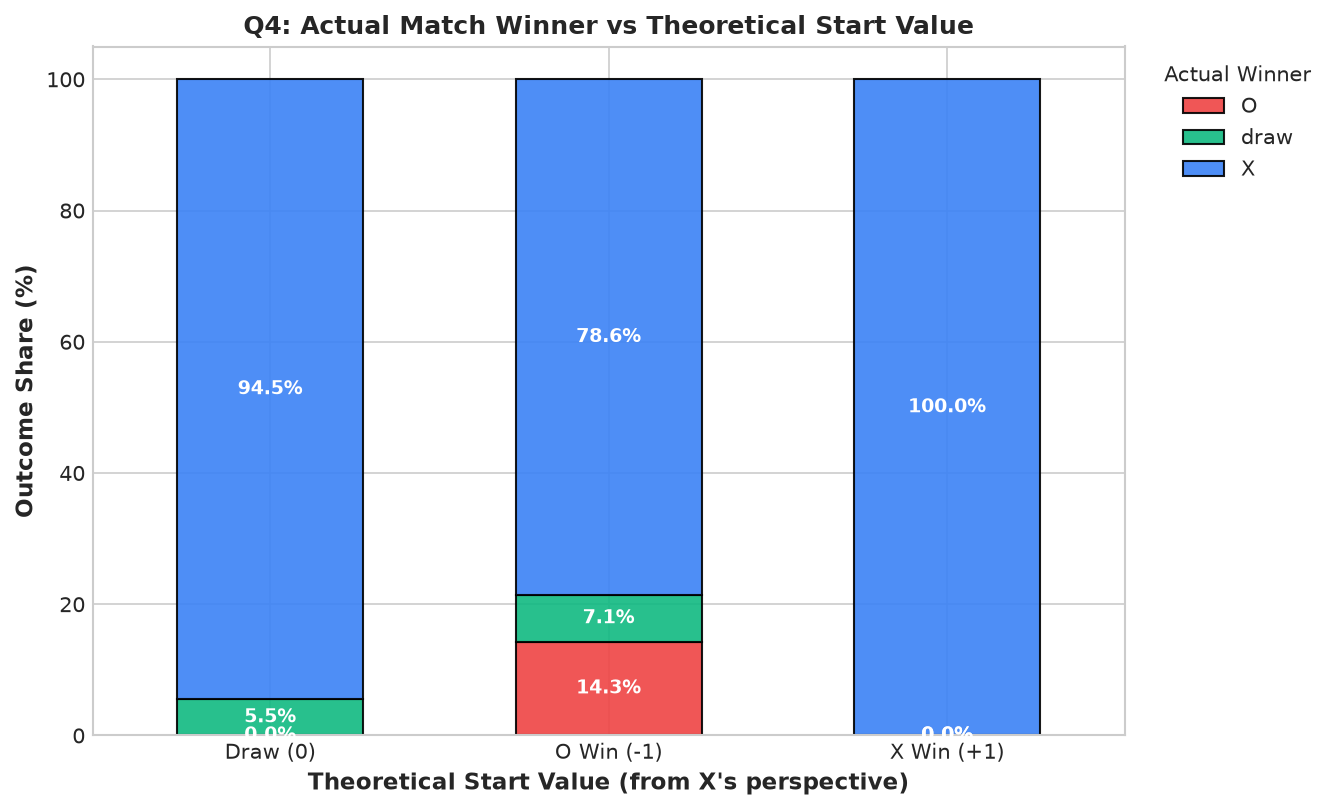

In [11]:
fig, ax = plt.subplots(figsize=(9, 5.5))

outcome_colors = {'O': '#ef4444', 'X': '#3b82f6', 'draw': '#10b981'}
q4_crosstab_pct[['O', 'draw', 'X']].plot(
    kind='bar', 
    stacked=True, 
    ax=ax, 
    color=[outcome_colors['O'], outcome_colors['draw'], outcome_colors['X']],
    edgecolor='black',
    alpha=0.9,
    width=0.55
)

ax.set_title("Q4: Actual Match Winner vs Theoretical Start Value", fontsize=12)
ax.set_xlabel("Theoretical Start Value (from X's perspective)")
ax.set_ylabel("Outcome Share (%)")
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
ax.legend(title='Actual Winner', bbox_to_anchor=(1.02, 1), loc='upper left')

for c in ax.containers:
    ax.bar_label(c, label_type='center', fmt='%.1f%%', color='white', fontweight='bold', fontsize=9)

plt.tight_layout()
plt.show()

### تحلیل و تفسیر سه‌بخشی سؤال ۴:
* **مشاهده (Observation):** حتی زمانی که ارزش تئوریک شروع بازی به نفع O بوده است (`start_value = -1`، ۱۴ بازی)، عامل هوشمند X در ۷۸.۶٪ مواقع (۱۱ بازی) توانسته پیروز شود و تنها در ۲ بازی شکست خورده است. در حالات مساوی (`start_value = 0`)، X در ۹۴.۵٪ مواقع به برد رسیده است.
* **دلیل (Reason):** ارزیابی Minimax بر این فرض استوار است که حریف نیز بازی بهینه و خصمانه انجام می‌دهد. اما حریف O در شبیه‌سازی حرکات تصادفی انجام داده و اشتباهات فاحشی مرتکب می‌شود؛ عامل X این اشتباهات را بی‌درنگ شناسایی و مجازات می‌کند.
* **نتیجه (Conclusion):** فرض بازی بهینه حریف در مینیمکس یک کران پایین اطمینان‌بخش است؛ عامل در برابر حریفان ضعیف‌تر یا تصادفی عملکردی به مراتب فراتر از پیش‌بینی تئوریک نشان می‌دهد.

---
## سؤال ۵: طول بازی‌ها (`moves`) به تفکیک نتیجه نهایی
**هدف:** بررسی تعداد گام‌های انجام‌شده تا رسیدن به نتیجه قطعی و مقایسه سرعت خاتمه بازی‌های برنده با بازی‌های مساوی.

In [12]:
moves_stats = df.groupby('winner')['moves'].agg(['count', 'mean', 'std', 'min', 'median', 'max']).round(2)
print("آمار توصیفی تعداد حرکت‌ها (Moves) بر اساس نتیجه نهایی:")
display(moves_stats)

آمار توصیفی تعداد حرکت‌ها (Moves) بر اساس نتیجه نهایی:
        count  mean   std  min  median  max
winner                                     
O           2  2.50  0.71    2     2.5    3
X         191  4.50  1.60    1     4.0    8
draw        7  6.71  1.25    6     6.0    9


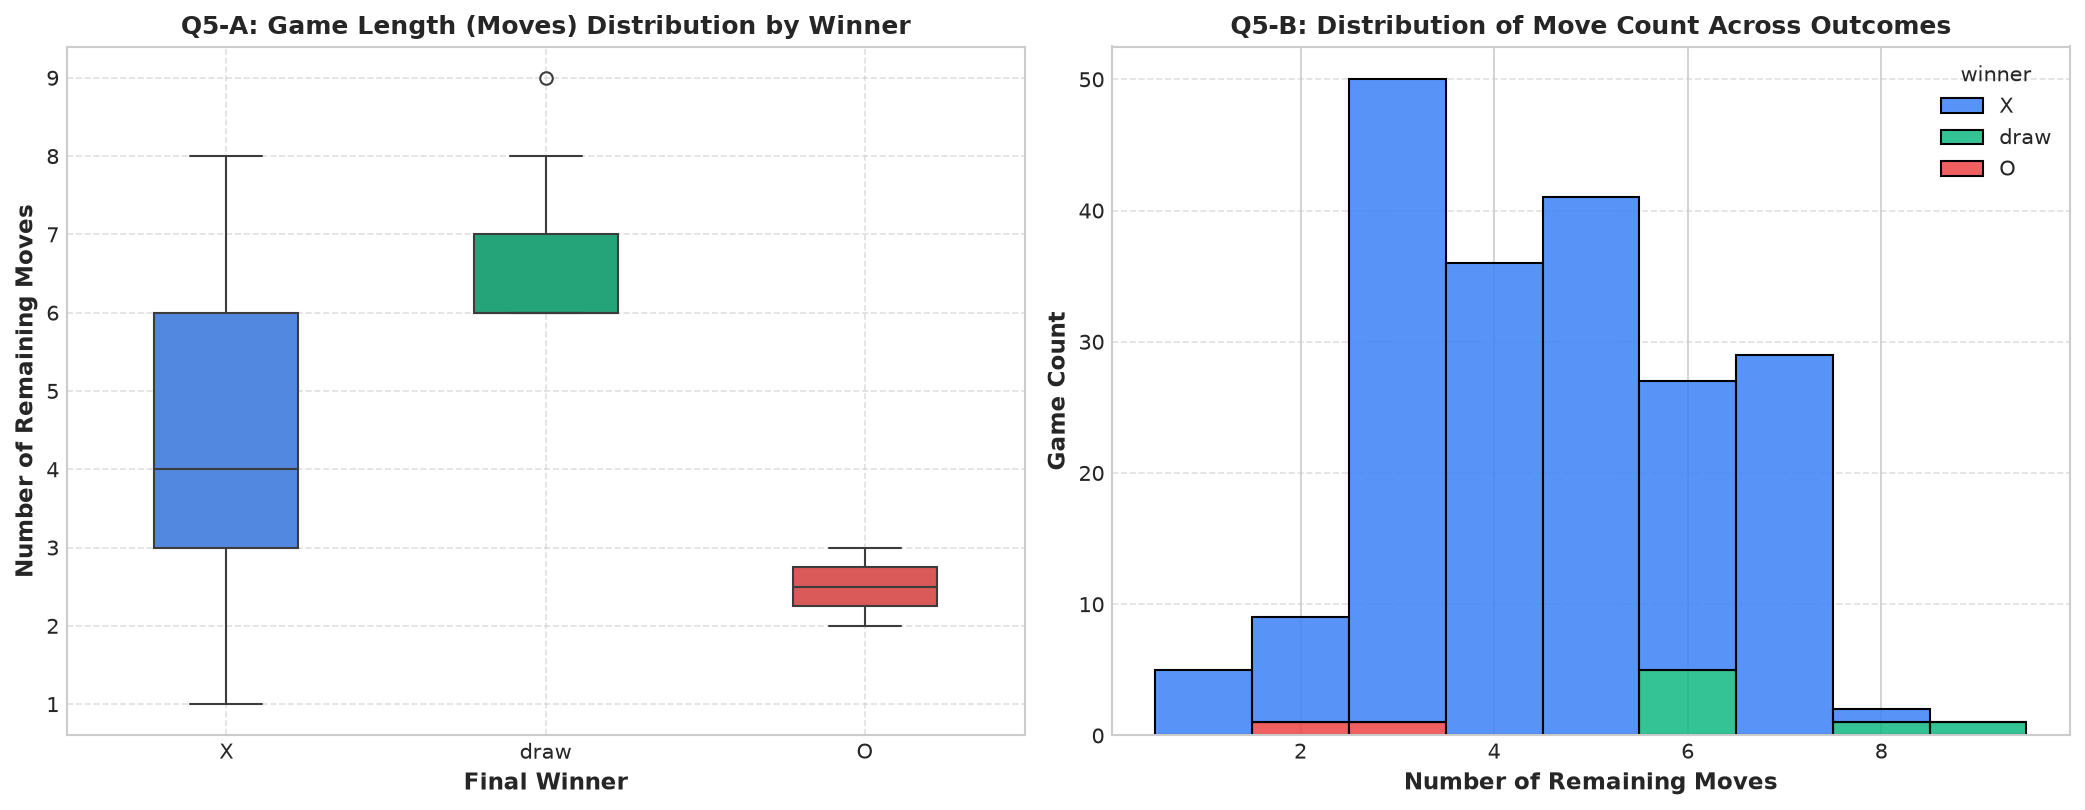

In [13]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))

# نمودار جعبه‌ای طول بازی
sns.boxplot(data=df, x='winner', y='moves', palette={'X': '#3b82f6', 'O': '#ef4444', 'draw': '#10b981'}, ax=ax1, width=0.45)
ax1.set_title("Q5-A: Game Length (Moves) Distribution by Winner", fontsize=12)
ax1.set_xlabel("Final Winner")
ax1.set_ylabel("Number of Remaining Moves")
ax1.grid(True, linestyle="--", alpha=0.6)

# نمودار توزیع فراوانی / هیستوگرام با تفکیک برنده
sns.histplot(data=df, x='moves', hue='winner', multiple='stack', palette={'X': '#3b82f6', 'O': '#ef4444', 'draw': '#10b981'}, 
             ax=ax2, discrete=True, edgecolor='black', alpha=0.85)
ax2.set_title("Q5-B: Distribution of Move Count Across Outcomes", fontsize=12)
ax2.set_xlabel("Number of Remaining Moves")
ax2.set_ylabel("Game Count")
ax2.grid(axis='y', linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()

### تحلیل و تفسیر سه‌بخشی سؤال ۵:
* **مشاهده (Observation):** بازی‌های منجر به تساوی بیشترین تعداد حرکت (میانگین ۶.۷۱) و بازی‌های منجر به برد O کمترین تعداد حرکت (میانگین ۲.۵۰) را دارند. بردهای X در میانه با میانگین ۴.۵۰ قرار دارند.
* **دلیل (Reason):** برای تساوی، صفحه باید تقریباً یا کاملاً پر شود (حداقل ۸ یا ۹ خانه). از طرفی، بردهای سریع O زمانی رخ داده که تخته با حرکت‌های اولیه پر بوده و O تنها با یک حرکت اشتباه یا تله آنی برنده شده است، در حالی که X بازی را به طور مداوم و تاکتیکی در ۴ تا ۵ حرکت به پیروزی می‌رساند.
* **نتیجه (Conclusion):** تساوی گران‌ترین نتیجه از منظر طول بازی است و بردهای قاطع عامل در کمترین گام‌های ممکن حاصل می‌شود.

---
## سؤال ۶: اثر نوبت اولیه (`to_move`) بر احتمال پیروزی عامل
**هدف:** بررسی میزان حساسیت عملکرد عامل به تقدم نوبت در سناریوهایی که بازی از پیش با نوبت O یا X تنظیم شده است.

In [14]:
q6_crosstab_raw = pd.crosstab(df['to_move'], df['winner'])
q6_crosstab_pct = (pd.crosstab(df['to_move'], df['winner'], normalize='index') * 100).round(1)

print("توزیع نتایج بر حسب نوبت شروع:")
display(q6_crosstab_raw)

print("\nدرصد نتایج بر حسب نوبت شروع:")
display(q6_crosstab_pct)

توزیع نتایج بر حسب نوبت شروع:
winner   O    X  draw
to_move              
O        1   67     6
X        1  124     1

درصد نتایج بر حسب نوبت شروع:
winner     O     X  draw
to_move                 
O        1.4  90.5   8.1
X        0.8  98.4   0.8


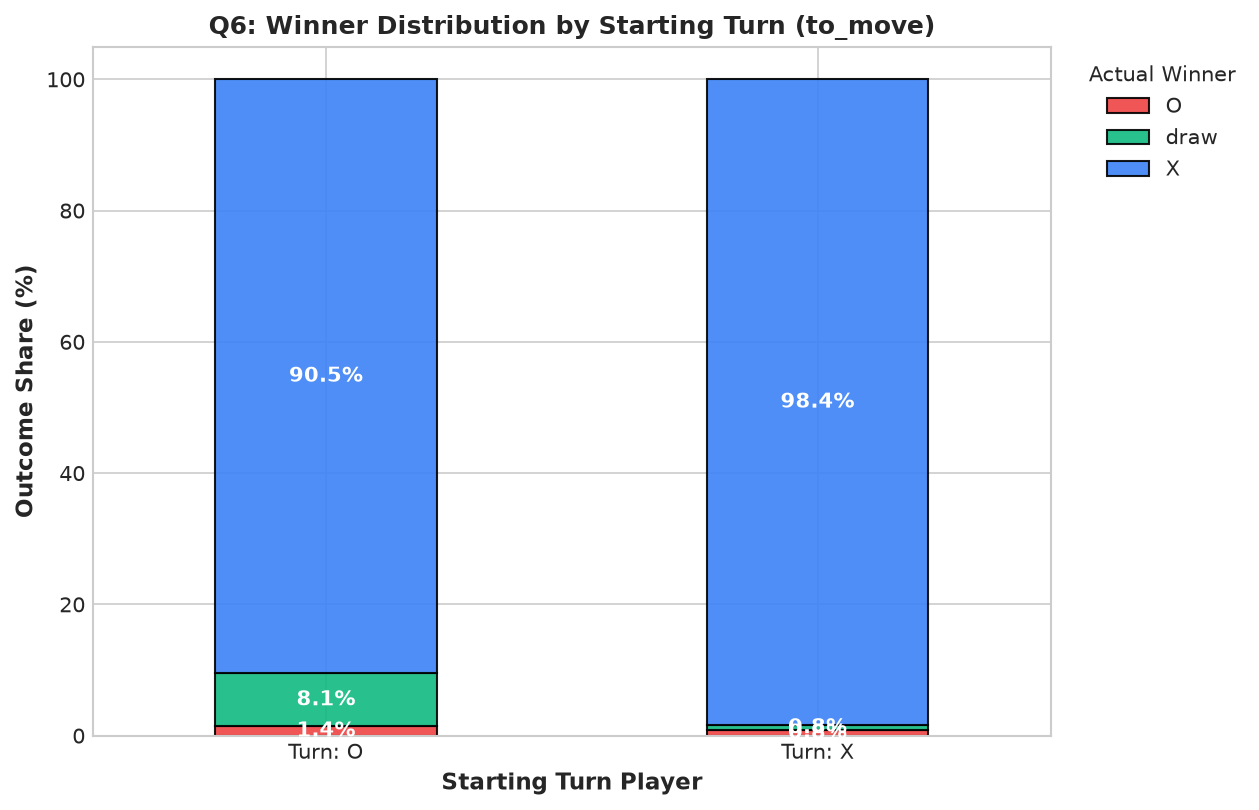

In [15]:
fig, ax = plt.subplots(figsize=(8.5, 5.5))

q6_crosstab_pct[['O', 'draw', 'X']].plot(
    kind='bar', 
    stacked=True, 
    ax=ax, 
    color=[outcome_colors['O'], outcome_colors['draw'], outcome_colors['X']],
    edgecolor='black',
    alpha=0.9,
    width=0.45
)

ax.set_title("Q6: Winner Distribution by Starting Turn (to_move)", fontsize=12)
ax.set_xlabel("Starting Turn Player")
ax.set_ylabel("Outcome Share (%)")
ax.set_xticklabels(["Turn: O", "Turn: X"], rotation=0)
ax.legend(title='Actual Winner', bbox_to_anchor=(1.02, 1), loc='upper left')

for c in ax.containers:
    ax.bar_label(c, label_type='center', fmt='%.1f%%', color='white', fontweight='bold', fontsize=10)

plt.tight_layout()
plt.show()

### تحلیل و تفسیر سه‌بخشی سؤال ۶:
* **مشاهده (Observation):** نوبت دهی آغازین تأثیر بسیار اندکی بر نرخ برد کلی عامل هوشمند X دارد؛ چه نوبت با X باشد (۹۸٪ برد) و چه با O (۹۱٪ برد)، عامل X قاطعانه برنده میدان است، اگرچه سهم مساوی‌ها در صورت نوبت O به ۸٪ افزایش می‌یابد.
* **دلیل (Reason):** تفکر چندگامی عامل X و اشتباهات مکرر حریف تصادفی باعث می‌شود اثر نوبت اولیه سریعاً خنثی شود، هرچند اعطای نوبت اول به O فرصت دفاعی بیشتری به حریف داده و احتمال تساوی را اندکی بالا می‌برد.
* **نتیجه (Conclusion):** عامل هوشمند نسبت به عدم تقارن نوبت‌دهی اولیه مقاوم است و بهینه بودن الگوریتم، کمبود نوبت اولیه را جبران می‌کند.

---
## داشبورد تجمیعی ۶ نمودار کلیدی تحلیل اکتشافی (EDA Dashboard)
در این بخش تمام ۶ نمودار تحلیل اکتشافی در قالب یک داشبورد منسجم و یکپارچه در ابعاد بزرگ و کیفیت بالا رسم می‌شوند.

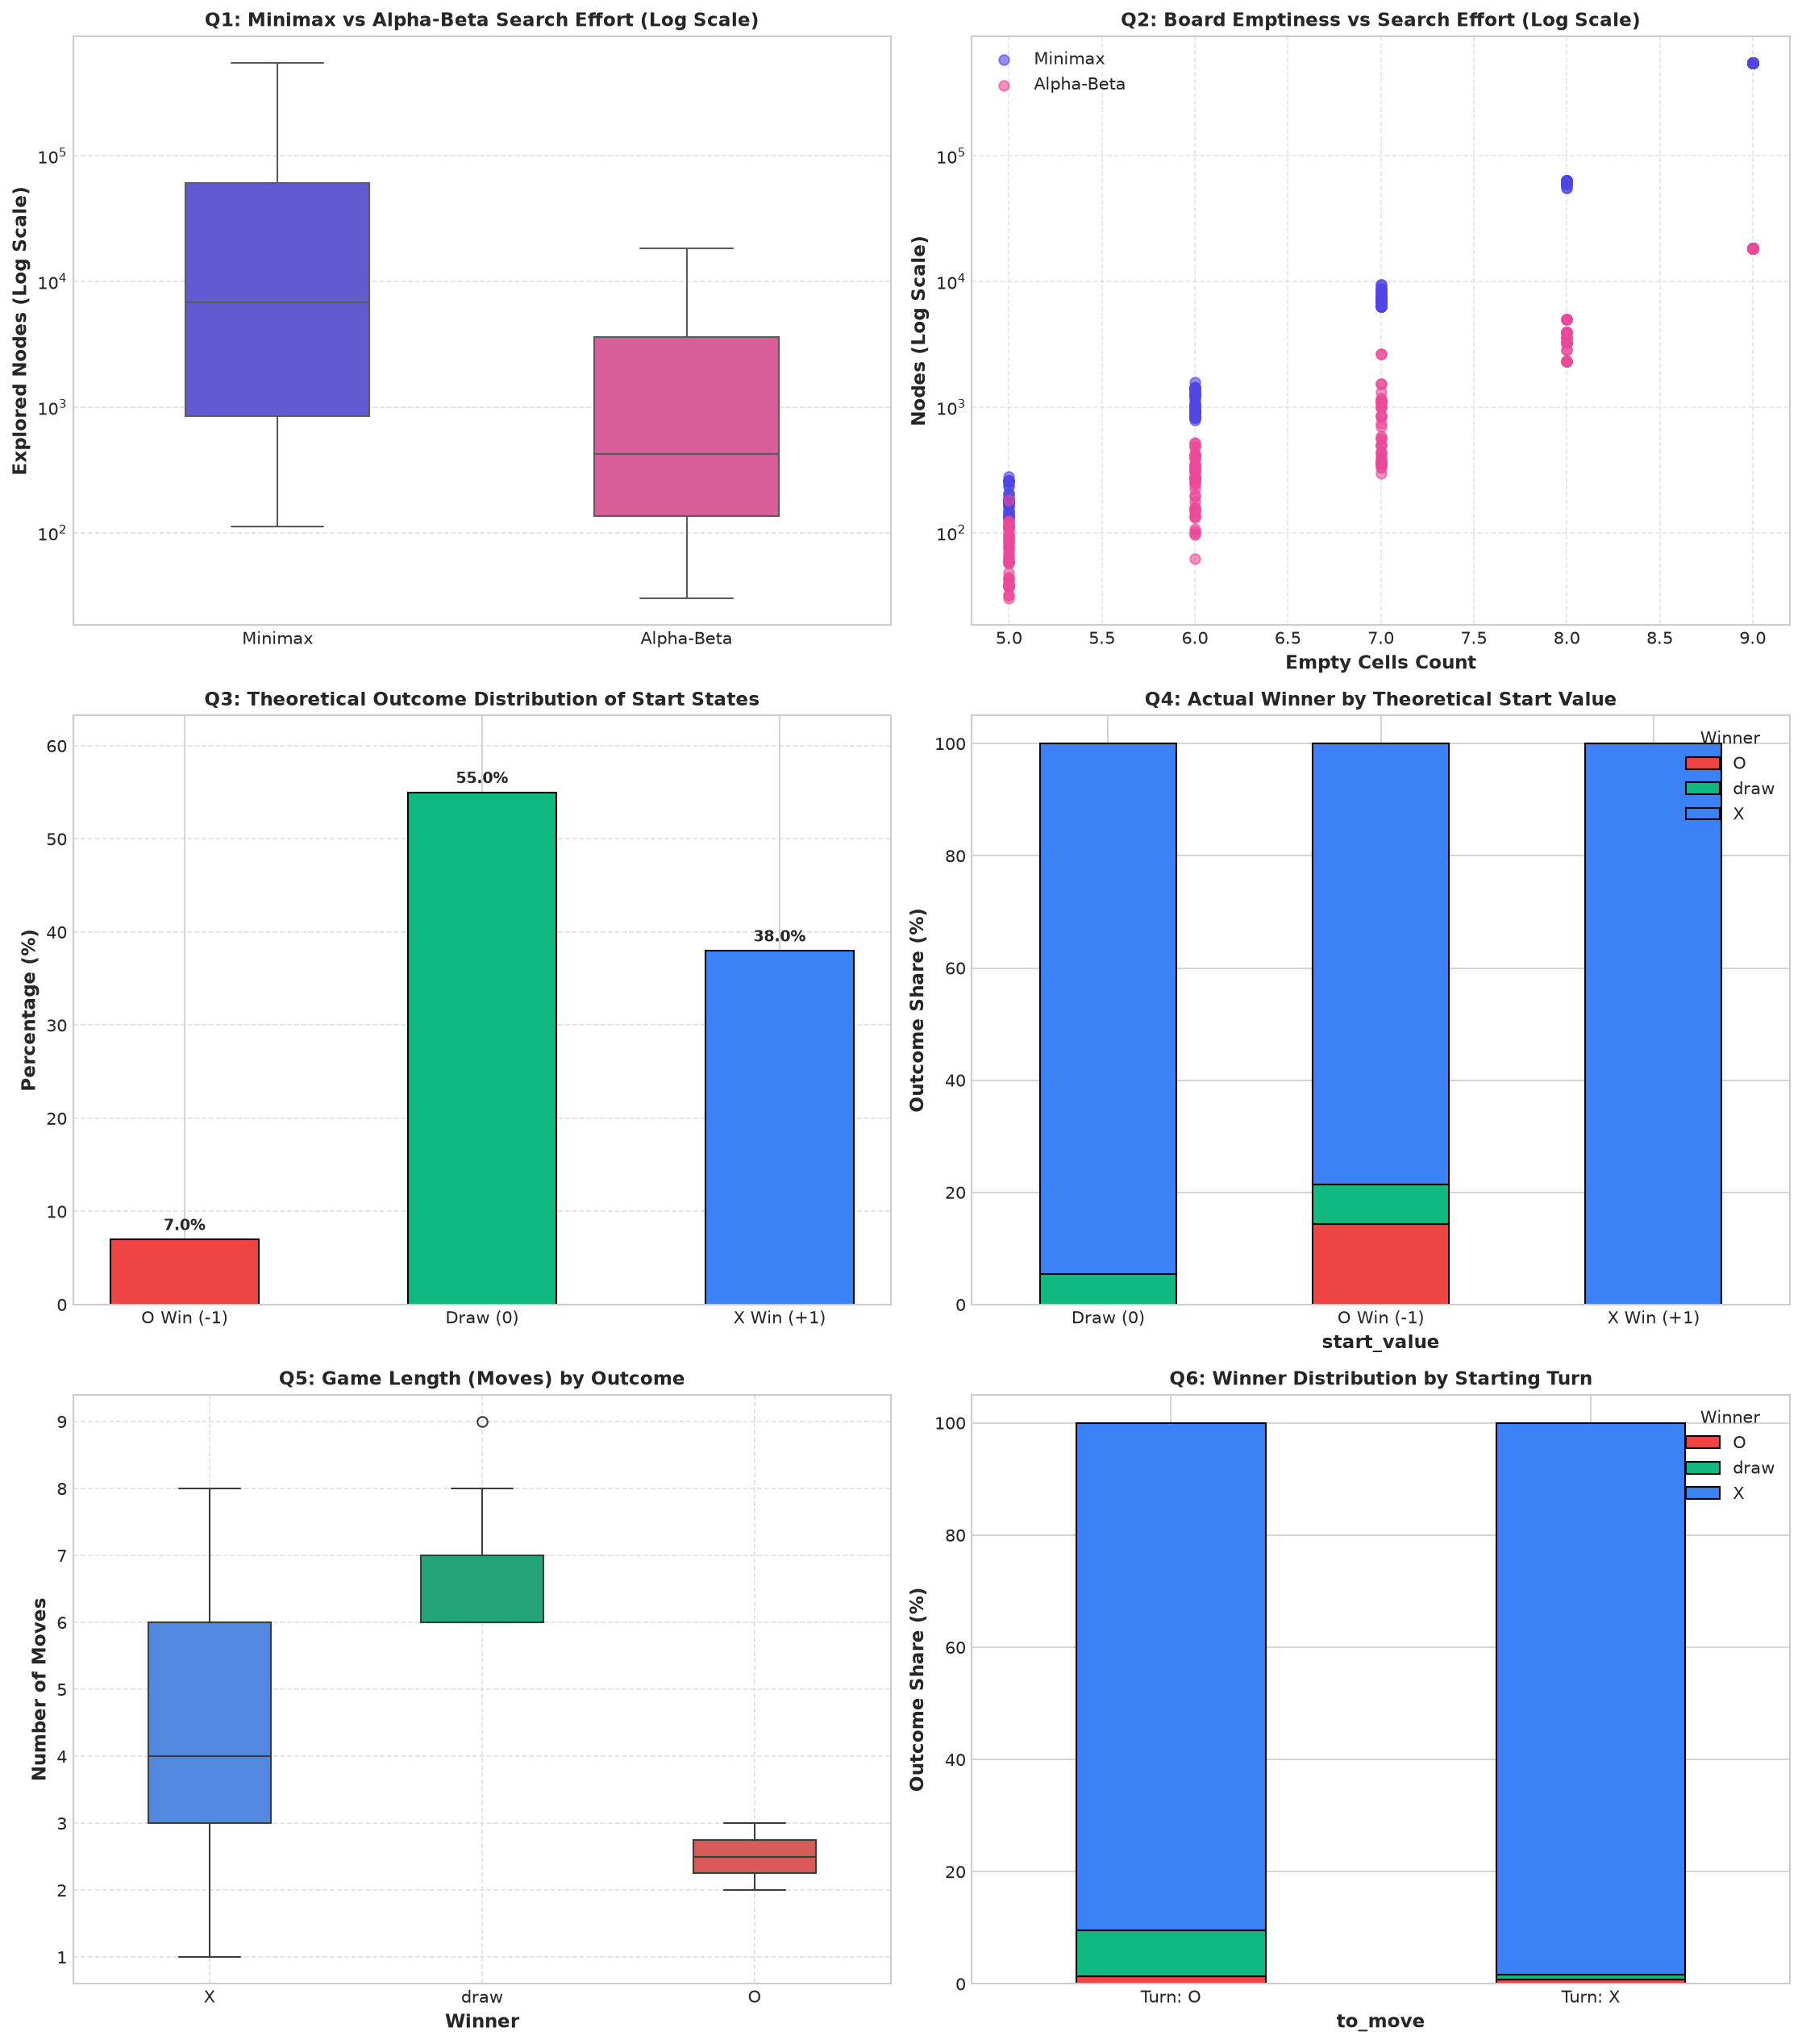

In [16]:
fig, axes = plt.subplots(3, 2, figsize=(15, 17))
plt.subplots_adjust(hspace=0.45, wspace=0.3)

# نمودار ۱: گره‌های لگاریتمی
sns.boxplot(data=df[['nodes_minimax', 'nodes_alphabeta']], log_scale=True, palette=['#4f46e5', '#ec4899'], ax=axes[0, 0], width=0.45)
axes[0, 0].set_title("Q1: Minimax vs Alpha-Beta Search Effort (Log Scale)", fontsize=11, fontweight='bold')
axes[0, 0].set_ylabel("Explored Nodes (Log Scale)")
axes[0, 0].set_xticklabels(["Minimax", "Alpha-Beta"])
axes[0, 0].grid(axis='y', linestyle='--', alpha=0.6)

# نمودار ۲: خانه‌های خالی در برابر گره‌ها
axes[0, 1].scatter(df['empty_cells'], df['nodes_minimax'], color='#4f46e5', alpha=0.6, label='Minimax')
axes[0, 1].scatter(df['empty_cells'], df['nodes_alphabeta'], color='#ec4899', alpha=0.6, label='Alpha-Beta')
axes[0, 1].set_yscale('log')
axes[0, 1].set_title("Q2: Board Emptiness vs Search Effort (Log Scale)", fontsize=11, fontweight='bold')
axes[0, 1].set_xlabel("Empty Cells Count")
axes[0, 1].set_ylabel("Nodes (Log Scale)")
axes[0, 1].legend()
axes[0, 1].grid(True, linestyle='--', alpha=0.5)

# نمودار ۳: توزیع پیامد تئوریک شروع
bars3 = axes[1, 0].bar(q3_df.index, q3_df['Percentage (%)'], color=['#ef4444', '#10b981', '#3b82f6'], edgecolor='black', width=0.5)
axes[1, 0].set_title("Q3: Theoretical Outcome Distribution of Start States", fontsize=11, fontweight='bold')
axes[1, 0].set_ylabel("Percentage (%)")
for bar in bars3:
    axes[1, 0].annotate(f"{bar.get_height():.1f}%", 
                        (bar.get_x() + bar.get_width() / 2., bar.get_height() + 1), 
                        ha='center', fontsize=9, fontweight='bold')
axes[1, 0].set_ylim(0, max(q3_df['Percentage (%)']) * 1.15)
axes[1, 0].grid(axis='y', linestyle='--', alpha=0.6)

# نمودار ۴: برنده واقعی بر اساس ارزش شروع
q4_crosstab_pct[['O', 'draw', 'X']].plot(
    kind='bar', stacked=True, ax=axes[1, 1], 
    color=['#ef4444', '#10b981', '#3b82f6'], edgecolor='black', width=0.5
)
axes[1, 1].set_title("Q4: Actual Winner by Theoretical Start Value", fontsize=11, fontweight='bold')
axes[1, 1].set_ylabel("Outcome Share (%)")
axes[1, 1].set_xticklabels(axes[1, 1].get_xticklabels(), rotation=0)
axes[1, 1].legend(title='Winner', loc='upper right')

# نمودار ۵: طول بازی بر اساس برنده
sns.boxplot(data=df, x='winner', y='moves', palette={'X': '#3b82f6', 'O': '#ef4444', 'draw': '#10b981'}, ax=axes[2, 0], width=0.45)
axes[2, 0].set_title("Q5: Game Length (Moves) by Outcome", fontsize=11, fontweight='bold')
axes[2, 0].set_xlabel("Winner")
axes[2, 0].set_ylabel("Number of Moves")
axes[2, 0].grid(True, linestyle='--', alpha=0.6)

# نمودار ۶: اثر نوبت شروع
q6_crosstab_pct[['O', 'draw', 'X']].plot(
    kind='bar', stacked=True, ax=axes[2, 1], 
    color=['#ef4444', '#10b981', '#3b82f6'], edgecolor='black', width=0.45
)
axes[2, 1].set_title("Q6: Winner Distribution by Starting Turn", fontsize=11, fontweight='bold')
axes[2, 1].set_ylabel("Outcome Share (%)")
axes[2, 1].set_xticklabels(["Turn: O", "Turn: X"], rotation=0)
axes[2, 1].legend(title='Winner', loc='upper right')

plt.tight_layout()
plt.show()

---
## نتیجه‌گیری نهایی و دستاوردهای تحلیلی گام سوم:
۱. **راندمان فوق‌العاده Alpha-Beta Pruning:** هرس آلفا-بتا در ابتدای بازی بار محاسباتی را تا ۳۰ برابر کاهش می‌دهد و در کل ۲۰۰ بازی، متوسط کاهش بیش از ۹۲.۸٪ است.  
۲. **رابطه مستقیم عمق با هزینه جستجو:** همبستگی بالای ۸۰ درصدی نشان می‌دهد که بازی در مراحل پایانی نیاز پردازشی بسیار اندکی دارد.  
۳. **قاطعیت عامل هوشمند در برابر حریف تصادفی:** نرخ برد کلی ۹۵.۵٪ و توانایی پیروزی در ۷۸.۶٪ حالات تئوریک بازنده اثبات می‌کند که عامل به سرعت خطاهای حریف را به فرصت تبدیل می‌کند.  
۴. **استقلال عملکرد از نوبت:** نوبت اولیه هرچند احتمال تساوی را از ۱٪ به ۸٪ در نوبت O تغییر می‌دهد، اما نرخ برد عامل را در بالای ۹۱٪ نگه می‌دارد.